<a href="https://colab.research.google.com/github/alelopez9411-ux/proyecto-marketing-analytics/blob/main/marketing_rfm_cohortes_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

ruta = "/online_retail_II.csv"
df = pd.read_csv(ruta, dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])

print("Filas y columnas:", df.shape)
print()
print(df.columns.tolist())
print()
print("Valores vacíos por columna:")
print(df.isna().sum())
print()
print("Rango de fechas:", df["InvoiceDate"].min(), "→", df["InvoiceDate"].max())
df.head()

Filas y columnas: (1067371, 8)

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Valores vacíos por columna:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Rango de fechas: 2009-12-01 07:45:00 → 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
n0 = len(df)

# 1) Sin cliente identificado
d = df.dropna(subset=["Customer ID"]).copy()
n1 = len(d)

# 2) Devoluciones y cancelaciones (facturas que empiezan con "C")
devoluciones = d["Invoice"].str.startswith("C").sum()
d = d[~d["Invoice"].str.startswith("C")]
n2 = len(d)

# 3) Cantidades o precios que no tienen sentido (<= 0)
d = d[(d["Quantity"] > 0) & (d["Price"] > 0)]
n3 = len(d)

# Columnas útiles
d["Customer ID"] = d["Customer ID"].astype(int)
d["Ingreso"] = d["Quantity"] * d["Price"]

print(f"Filas originales:            {n0:,}")
print(f"Sin cliente (quitadas):      {n0 - n1:,}")
print(f"Devoluciones (quitadas):     {n1 - n2:,}")
print(f"Cantidad/precio <= 0:        {n2 - n3:,}")
print(f"Filas finales:               {n3:,}")
print()
print("Clientes únicos:", d["Customer ID"].nunique())
print("Facturas únicas:", d["Invoice"].nunique())
print("Ingreso total:", round(d["Ingreso"].sum(), 2))

Filas originales:            1,067,371
Sin cliente (quitadas):      243,007
Devoluciones (quitadas):     18,744
Cantidad/precio <= 0:        71
Filas finales:               805,549

Clientes únicos: 5878
Facturas únicas: 36969
Ingreso total: 17743429.18


In [ ]:
# Fecha de referencia: un día después de la última compra del dataset
hoy = d["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = d.groupby("Customer ID").agg(
    Recencia=("InvoiceDate", lambda x: (hoy - x.max()).days),
    Frecuencia=("Invoice", "nunique"),
    Monto=("Ingreso", "sum"),
).reset_index()

print("Fecha de referencia:", hoy)
print()
print(rfm[["Recencia", "Frecuencia", "Monto"]].describe().round(1))
rfm.head()

Fecha de referencia: 2011-12-10 12:50:00

       Recencia  Frecuencia     Monto
count    5878.0      5878.0    5878.0
mean      201.3         6.3    3018.6
std       209.3        13.0   14737.7
min         1.0         1.0       3.0
25%        26.0         1.0     348.8
50%        96.0         3.0     898.9
75%       380.0         7.0    2307.1
max       739.0       398.0  608821.6


,Customer ID,Recencia,Frecuencia,Monto
0,12346,326,12,77556.46
1,12347,2,8,5633.32
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40


In [ ]:
import numpy as np

# Puntaje 1-5 (5 = mejor). Recencia va al revés: menos días = mejor.
rfm["R"] = pd.qcut(rfm["Recencia"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frecuencia"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monto"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Segmentos según R y F
condiciones = [
    (rfm["R"] >= 4) & (rfm["F"] >= 4),
    (rfm["R"] >= 3) & (rfm["F"] >= 3),
    (rfm["R"] >= 4) & (rfm["F"] <= 2),
    (rfm["R"] <= 2) & (rfm["F"] >= 3),
    (rfm["R"] <= 2) & (rfm["F"] <= 2),
]
nombres = ["Campeones", "Leales", "Nuevos o prometedores", "En riesgo", "Dormidos"]
rfm["Segmento"] = np.select(condiciones, nombres, default="Necesitan atención")

resumen = rfm.groupby("Segmento").agg(
    clientes=("Customer ID", "count"),
    ingreso=("Monto", "sum"),
    recencia_mediana=("Recencia", "median"),
    frecuencia_mediana=("Frecuencia", "median"),
    monto_mediano=("Monto", "median"),
)
resumen["% clientes"] = (resumen["clientes"] / resumen["clientes"].sum() * 100).round(1)
resumen["% ingreso"] = (resumen["ingreso"] / resumen["ingreso"].sum() * 100).round(1)
resumen.sort_values("ingreso", ascending=False).round(0)

,clientes,ingreso,recencia_mediana,frecuencia_mediana,monto_mediano,% clientes,% ingreso
Segmento,,,,,,,
Campeones,1473,12251341.0,17.0,10.0,3465.0,25.0,69.0
Leales,1229,2589735.0,72.0,4.0,1232.0,21.0,15.0
En riesgo,825,1634976.0,374.0,4.0,1040.0,14.0,9.0
Dormidos,1526,668140.0,434.0,1.0,285.0,26.0,4.0
Nuevos o prometedores,441,394210.0,26.0,1.0,373.0,8.0,2.0
Necesitan atención,384,205028.0,93.0,1.0,370.0,6.0,1.0


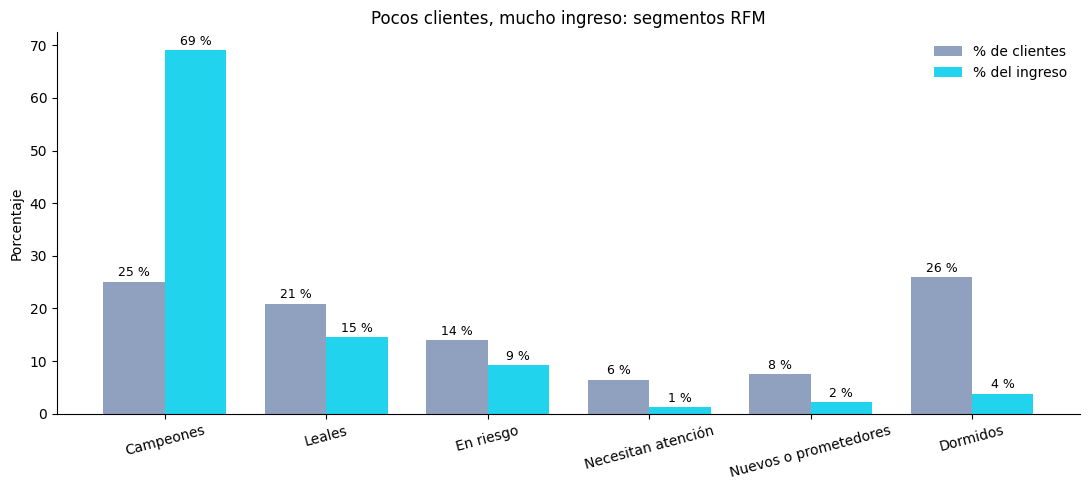

In [ ]:
import matplotlib.pyplot as plt

orden = ["Campeones", "Leales", "En riesgo", "Necesitan atención", "Nuevos o prometedores", "Dormidos"]
g = resumen.loc[orden]

x = np.arange(len(orden))
ancho = 0.38

fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - ancho/2, g["% clientes"], ancho, label="% de clientes", color="#8FA1BF")
b2 = ax.bar(x + ancho/2, g["% ingreso"], ancho, label="% del ingreso", color="#22D3EE")

for barras in (b1, b2):
    for b in barras:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f"{b.get_height():.0f} %",
                ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(orden, rotation=15)
ax.set_ylabel("Porcentaje")
ax.set_title("Pocos clientes, mucho ingreso: segmentos RFM")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("segmentos_rfm.png", dpi=150)
plt.show()

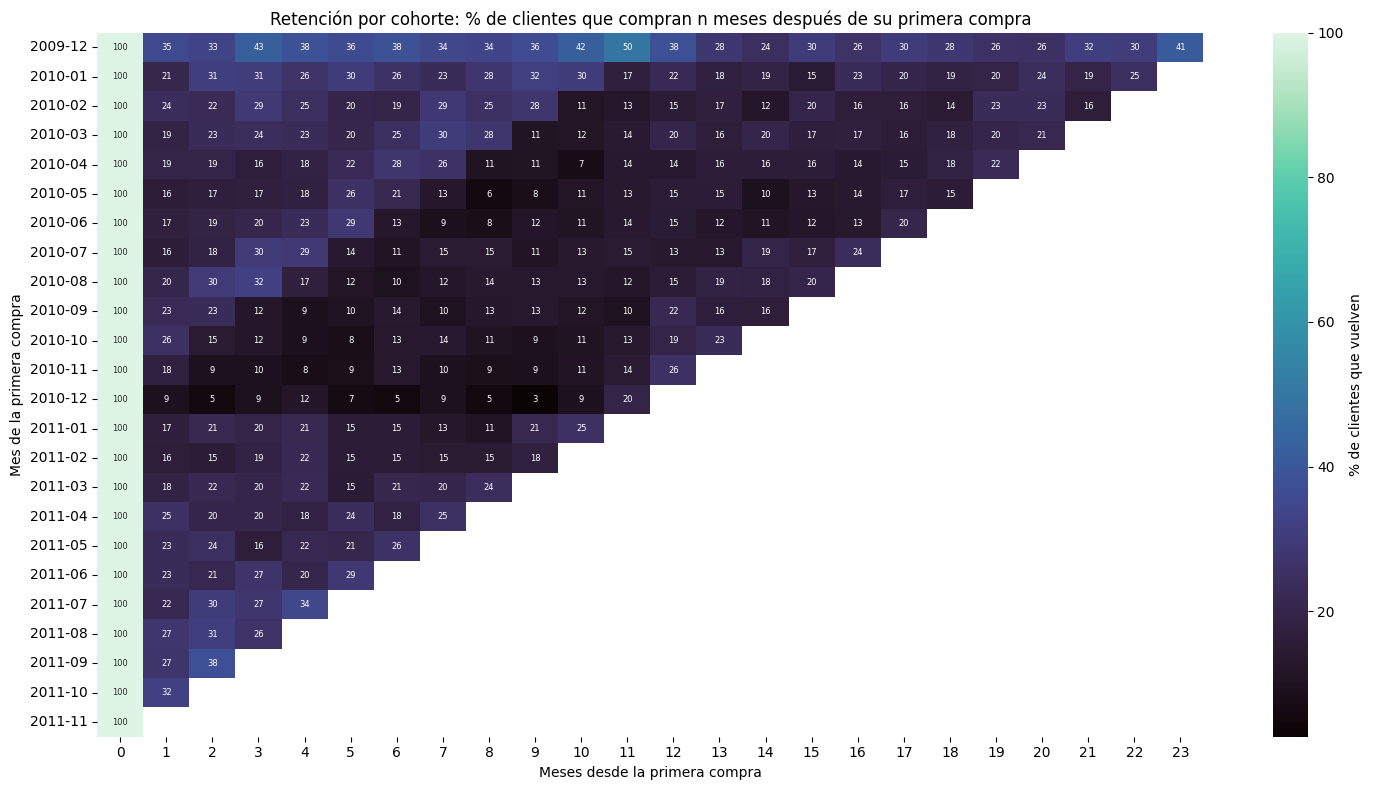

Retención promedio a 1, 3, 6 y 12 meses (%):
Periodo
1     20.8
3     20.9
6     17.2
12    17.9
dtype: float64


In [ ]:
import seaborn as sns

# Trabajamos por mes. Quitamos dic-2011 porque el dataset termina el día 9 (mes incompleto).
c = d.copy()
c["Mes"] = c["InvoiceDate"].dt.to_period("M")
c = c[c["Mes"] < "2011-12"]

# Cohorte = mes de la primera compra de cada cliente
c["Cohorte"] = c.groupby("Customer ID")["Mes"].transform("min")
c["Periodo"] = (c["Mes"] - c["Cohorte"]).apply(lambda x: x.n)

tabla = c.groupby(["Cohorte", "Periodo"])["Customer ID"].nunique().unstack()
retencion = tabla.div(tabla[0], axis=0) * 100
retencion.index = retencion.index.astype(str)

plt.figure(figsize=(15, 8))
sns.heatmap(retencion, cmap="mako", annot=True, fmt=".0f", annot_kws={"size": 6},
            cbar_kws={"label": "% de clientes que vuelven"})
plt.title("Retención por cohorte: % de clientes que compran n meses después de su primera compra")
plt.xlabel("Meses desde la primera compra")
plt.ylabel("Mes de la primera compra")
plt.tight_layout()
plt.savefig("cohortes_retencion.png", dpi=150)
plt.show()

# Retención promedio (sin la primera cohorte, ver nota)
prom = retencion.iloc[1:].mean().round(1)
print("Retención promedio a 1, 3, 6 y 12 meses (%):")
print(prom[[1, 3, 6, 12]])

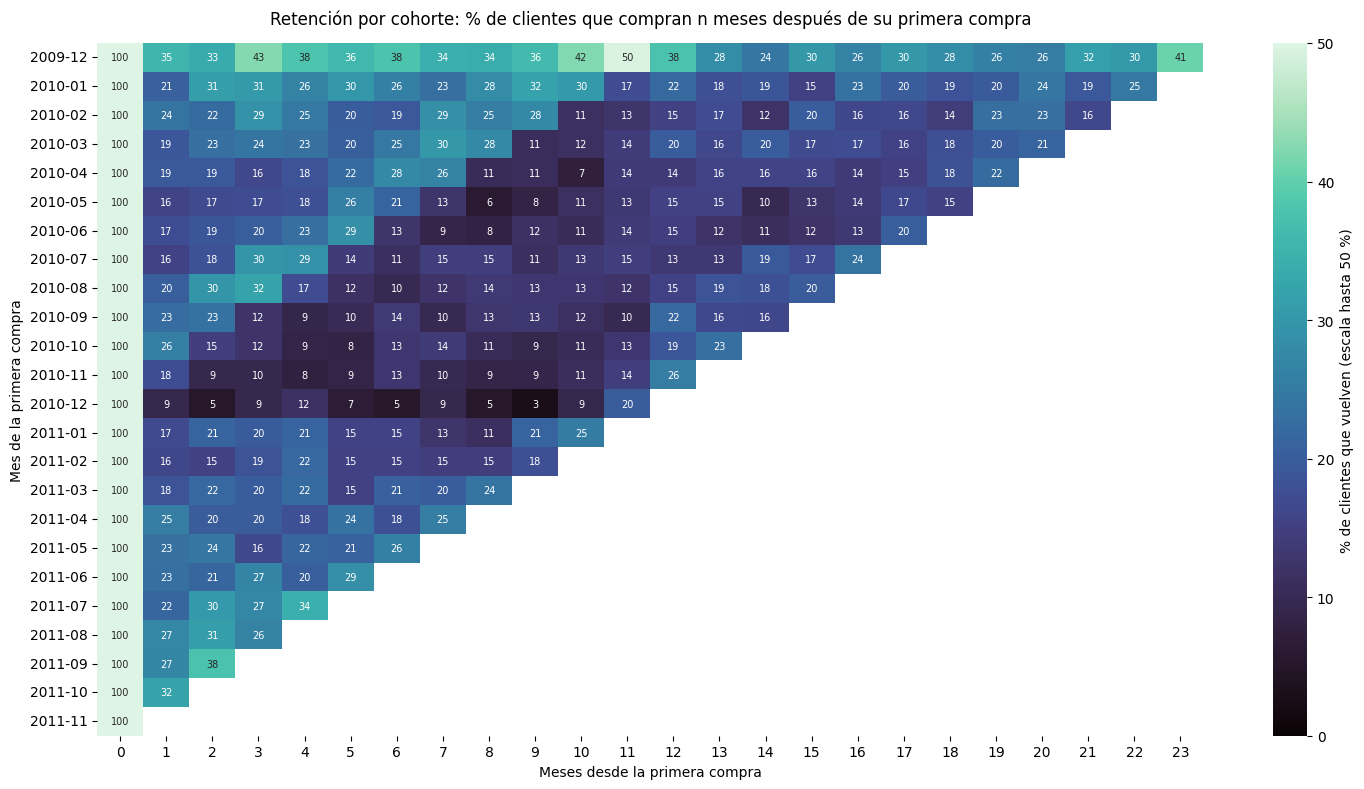

In [ ]:
plt.figure(figsize=(15, 8))
sns.heatmap(retencion, cmap="mako", vmin=0, vmax=50, annot=True, fmt=".0f",
            annot_kws={"size": 7}, cbar_kws={"label": "% de clientes que vuelven (escala hasta 50 %)"})
plt.title("Retención por cohorte: % de clientes que compran n meses después de su primera compra", pad=14)
plt.xlabel("Meses desde la primera compra")
plt.ylabel("Mes de la primera compra")
plt.tight_layout()
plt.savefig("cohortes_retencion.png", dpi=150)
plt.show()

Gini: 0.74
El 10 % de clientes que más gasta aporta el 64 % del ingreso
El 20 % de clientes que más gasta aporta el 77 % del ingreso


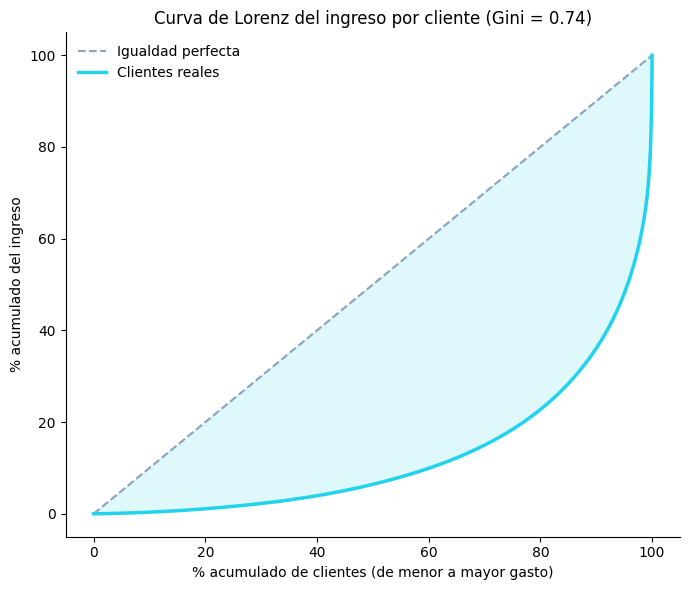

In [ ]:
m = rfm["Monto"].sort_values().reset_index(drop=True)   # de menor a mayor
n = len(m)
x = np.arange(n + 1) / n * 100
y = np.concatenate([[0], m.cumsum() / m.sum() * 100])

gini = 1 - 2 * np.sum((y[1:] + y[:-1]) / 2) / n / 100

# % del ingreso que aporta el 10 % y el 20 % de clientes con mayor gasto
desc = rfm["Monto"].sort_values(ascending=False).reset_index(drop=True)
top10 = desc[: int(n * 0.10)].sum() / desc.sum() * 100
top20 = desc[: int(n * 0.20)].sum() / desc.sum() * 100

print(f"Gini: {gini:.2f}")
print(f"El 10 % de clientes que más gasta aporta el {top10:.0f} % del ingreso")
print(f"El 20 % de clientes que más gasta aporta el {top20:.0f} % del ingreso")

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 100], [0, 100], "--", color="#8FA1BF", label="Igualdad perfecta")
ax.plot(x, y, color="#22D3EE", linewidth=2.5, label="Clientes reales")
ax.fill_between(x, y, x, color="#22D3EE", alpha=0.15)
ax.set_xlabel("% acumulado de clientes (de menor a mayor gasto)")
ax.set_ylabel("% acumulado del ingreso")
ax.set_title(f"Curva de Lorenz del ingreso por cliente (Gini = {gini:.2f})")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("curva_lorenz.png", dpi=150)
plt.show()

In [ ]:
print(f"Gini: {gini:.2f}")
print(f"El 10 % de clientes que más gasta aporta el {top10:.0f} % del ingreso")
print(f"El 20 % de clientes que más gasta aporta el {top20:.0f} % del ingreso")
print()
print("Clientes:", n, "| Ingreso total:", round(rfm["Monto"].sum(), 2))

# Tablas para el dashboard de Power BI (Fase 4)
rfm.to_csv("rfm_clientes.csv", index=False)
resumen.reset_index().to_csv("rfm_segmentos.csv", index=False)
retencion.round(1).reset_index().to_csv("retencion_cohortes.csv", index=False)
print("Guardados: rfm_clientes.csv, rfm_segmentos.csv, retencion_cohortes.csv")

Gini: 0.74
El 10 % de clientes que más gasta aporta el 64 % del ingreso
El 20 % de clientes que más gasta aporta el 77 % del ingreso

Clientes: 5878 | Ingreso total: 17743429.18
Guardados: rfm_clientes.csv, rfm_segmentos.csv, retencion_cohortes.csv


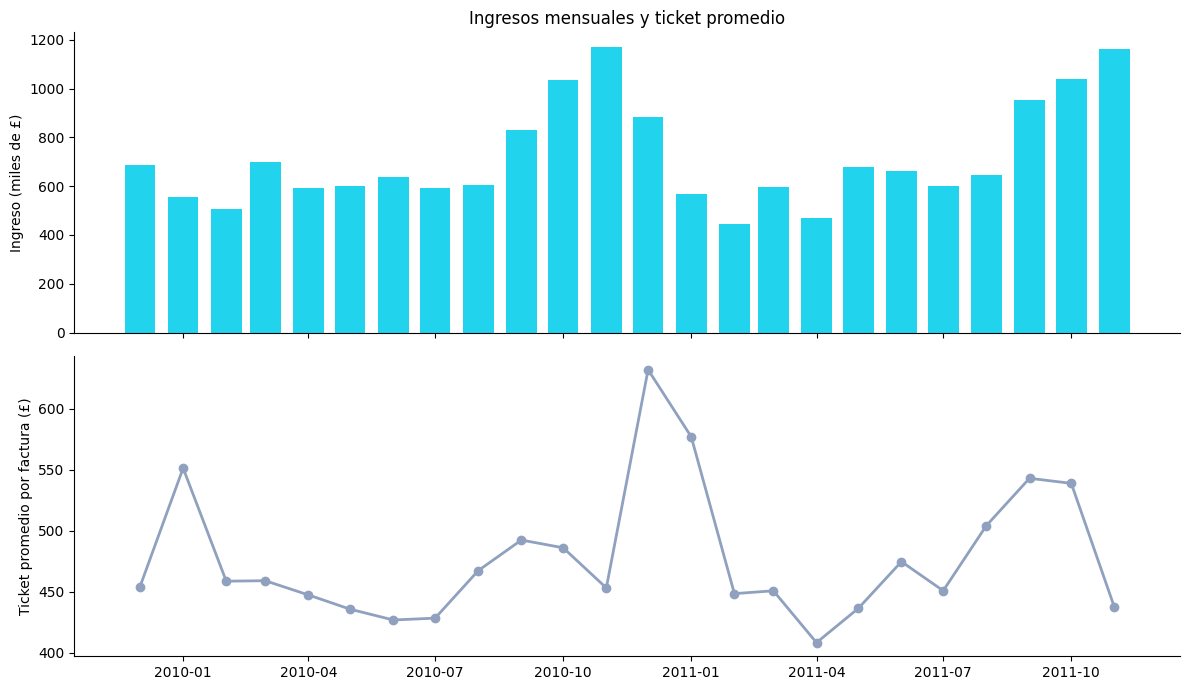

Mes de mayor ingreso: 2010-11 → 1172336
Mes de menor ingreso: 2011-02 → 447137
Ticket promedio general: 476.0


In [ ]:
mens = c.groupby("Mes").agg(
    ingreso=("Ingreso", "sum"),
    facturas=("Invoice", "nunique"),
    clientes=("Customer ID", "nunique"),
)
mens["ticket"] = mens["ingreso"] / mens["facturas"]
mens.index = mens.index.to_timestamp()

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

a1.bar(mens.index, mens["ingreso"] / 1000, width=22, color="#22D3EE")
a1.set_ylabel("Ingreso (miles de £)")
a1.set_title("Ingresos mensuales y ticket promedio")

a2.plot(mens.index, mens["ticket"], color="#8FA1BF", marker="o", linewidth=2)
a2.set_ylabel("Ticket promedio por factura (£)")

for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("ingresos_mensuales.png", dpi=150)
plt.show()

print("Mes de mayor ingreso:", mens["ingreso"].idxmax().strftime("%Y-%m"), "→", round(mens["ingreso"].max()))
print("Mes de menor ingreso:", mens["ingreso"].idxmin().strftime("%Y-%m"), "→", round(mens["ingreso"].min()))
print("Ticket promedio general:", round(c["Ingreso"].sum() / c["Invoice"].nunique(), 1))

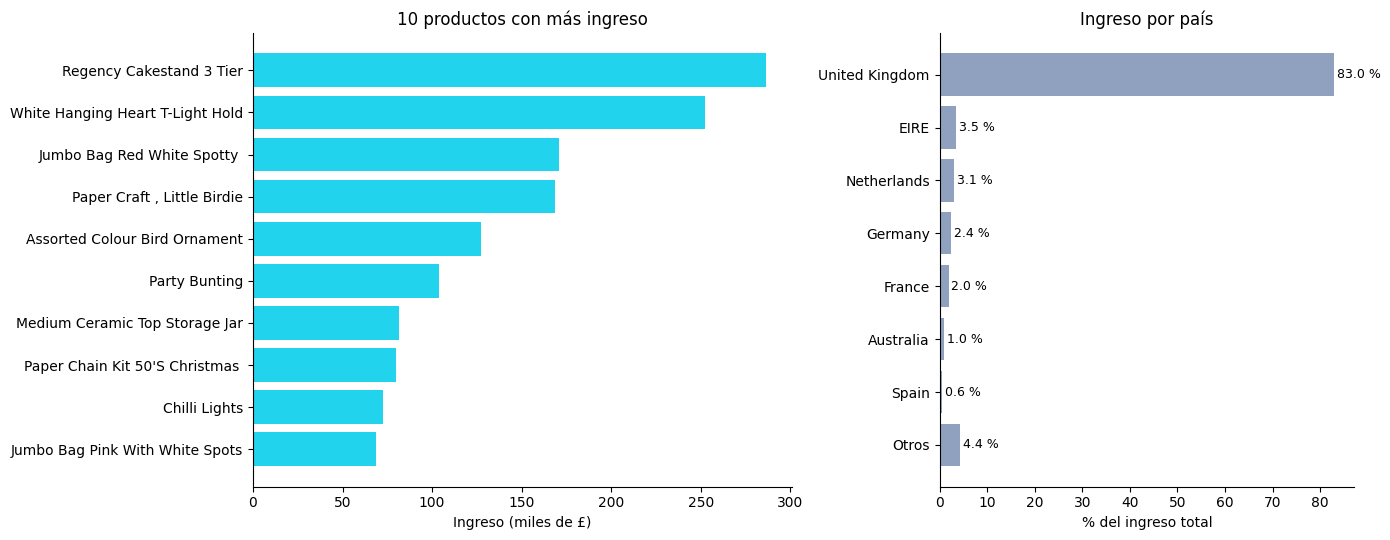

Reino Unido: 83.0 % del ingreso | Países distintos: 41


In [ ]:
# Quitamos códigos que no son productos (envío, comisiones, ajustes)
no_producto = ["POST", "DOT", "M", "BANK CHARGES", "C2", "CRUK", "AMAZONFEE", "ADJUST", "S", "B", "PADS"]
p = d[~d["StockCode"].isin(no_producto)]

top_prod = (p.groupby("StockCode").agg(producto=("Description", "first"), ingreso=("Ingreso", "sum"))
              .sort_values("ingreso", ascending=False).head(10))
top_prod["etiqueta"] = top_prod["producto"].str.title().str[:32]

pais = d.groupby("Country")["Ingreso"].sum().sort_values(ascending=False)
pais_pct = pais / pais.sum() * 100
otros = pais_pct.iloc[7:].sum()
pais_top = pd.concat([pais_pct.iloc[:7], pd.Series({"Otros": otros})])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

a1.barh(top_prod["etiqueta"][::-1], top_prod["ingreso"][::-1] / 1000, color="#22D3EE")
a1.set_xlabel("Ingreso (miles de £)")
a1.set_title("10 productos con más ingreso")

a2.barh(pais_top.index[::-1], pais_top.values[::-1], color="#8FA1BF")
a2.set_xlabel("% del ingreso total")
a2.set_title("Ingreso por país")
for i, v in enumerate(pais_top.values[::-1]):
    a2.text(v + 0.5, i, f"{v:.1f} %", va="center", fontsize=9)

for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("productos_paises.png", dpi=150)
plt.show()

print(f"Reino Unido: {pais_pct['United Kingdom']:.1f} % del ingreso | Países distintos: {d['Country'].nunique()}")

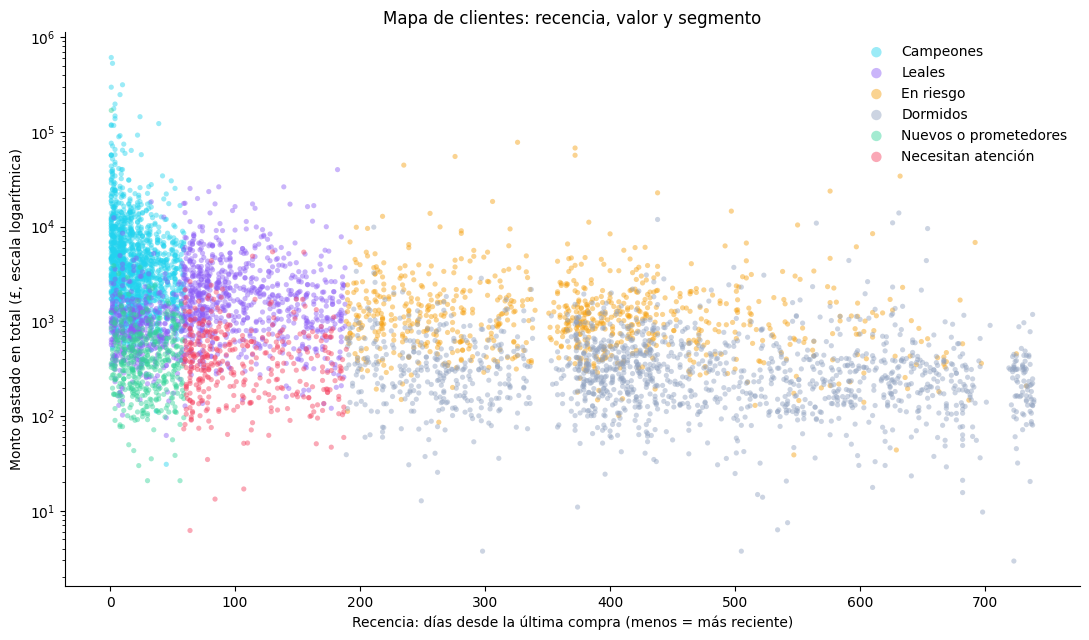

In [ ]:
colores = {
    "Campeones": "#22D3EE",
    "Leales": "#8B5CF6",
    "En riesgo": "#F59E0B",
    "Dormidos": "#8FA1BF",
    "Nuevos o prometedores": "#34D399",
    "Necesitan atención": "#F43F5E",
}

fig, ax = plt.subplots(figsize=(11, 6.5))
for seg, col in colores.items():
    s = rfm[rfm["Segmento"] == seg]
    ax.scatter(s["Recencia"], s["Monto"], s=14, alpha=0.45, color=col, label=seg, edgecolors="none")

ax.set_yscale("log")
ax.set_xlabel("Recencia: días desde la última compra (menos = más reciente)")
ax.set_ylabel("Monto gastado en total (£, escala logarítmica)")
ax.set_title("Mapa de clientes: recencia, valor y segmento")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, markerscale=2, loc="upper right")
plt.tight_layout()
plt.savefig("mapa_clientes.png", dpi=150)
plt.show()

In [ ]:
from scipy.stats import chi2_contingency
from statsmodels.stats.contingency_tables import Table2x2

# Una fila por cliente: ¿en qué cohorte entró y volvió al mes siguiente?
cli = c.groupby("Customer ID").agg(cohorte=("Cohorte", "first"))
volvieron = set(c.loc[c["Periodo"] == 1, "Customer ID"])
cli["volvio"] = cli.index.isin(volvieron)

# Cohortes donde el mes 1 ya se puede observar, sin la cohorte inicial (dic-2009)
cli = cli[(cli["cohorte"] >= pd.Period("2010-01")) & (cli["cohorte"] <= pd.Period("2011-10"))]
cli["temporada_alta"] = cli["cohorte"].dt.month.isin([10, 11, 12])

tabla = pd.crosstab(cli["temporada_alta"], cli["volvio"])
tabla.index = ["Resto del año", "Oct-Dic"]
tabla.columns = ["No volvió", "Volvió"]
print(tabla)
print()
print((tabla["Volvió"] / tabla.sum(axis=1) * 100).round(1).rename("% que volvió al mes 1"))

chi2, p, gl, _ = chi2_contingency(tabla.values)
t = Table2x2(tabla.values[::-1, ::-1])   # Oct-Dic contra el resto, "volvió" como evento
oddsr = t.oddsratio
ic = t.oddsratio_confint()
print()
print(f"Chi-cuadrado = {chi2:.2f}, gl = {gl}, p = {p:.4f}")
print(f"Odds ratio (Oct-Dic vs resto) = {oddsr:.2f}, IC 95 %: {ic[0]:.2f} a {ic[1]:.2f}")

               No volvió  Volvió
Resto del año       2947     758
Oct-Dic              767     232

Resto del año    20.5
Oct-Dic          23.2
Name: % que volvió al mes 1, dtype: float64

Chi-cuadrado = 3.45, gl = 1, p = 0.0631
Odds ratio (Oct-Dic vs resto) = 1.18, IC 95 %: 0.99 a 1.39
